<a href="https://colab.research.google.com/github/PierreCr/Computational-Pathology/blob/main/CanineHCC_ResNet18%2BLogReg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WSI canine HCC - Feature extraction using ResNet-18 and image classifier through Logistic Regression
# Pierre Cordier, DVM, PhD, Dipl.ECVP.
# 20/10/2026.


In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount("/content/drive/")

Mounted at /content/drive/


In [2]:
# Install OpenSlide
!apt-get update
!apt-get install -y openslide-tools
!pip install openslide-python

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Get:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:7 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [75.3 kB]
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Get:9 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,069 kB]
Get:10 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,549 kB]
Get:11 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.4 MB]
Get:12 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,410 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:14 h

In [3]:
# Import packages
import openslide
import matplotlib.pyplot as plt
import json
import numpy as np
import pandas as pd

WSI file: /content/drive/MyDrive/WSI_LHA0912-24/LHA0912-24_HES.mrxs
WSI vendor: mirax
WSI objective power: 20
WSI dimensions: (78753, 183759)
WSI level count: 9
WSI level dimensions: ((78753, 183759), (39376, 91879), (19688, 45939), (9844, 22969), (4922, 11484), (2461, 5742), (1230, 2871), (615, 1435), (307, 717))
WSI level downsamples: (1.0, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0, 128.0, 256.0)
WSI MPP-X: 0.2741
WSI MPP-Y: 0.2741


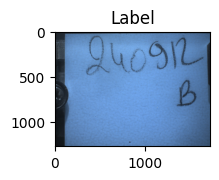

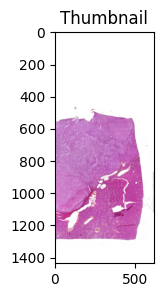

In [4]:
# WSI metadata and inspection
def inspect_wsi(path):
  slide = openslide.OpenSlide(path)
  print(f"WSI file: {path}")
  print(f"WSI vendor: {slide.properties['openslide.vendor']}")
  print(f"WSI objective power: {slide.properties['openslide.objective-power']}")
  print(f"WSI dimensions: {slide.dimensions}")
  print(f"WSI level count: {slide.level_count}")
  print(f"WSI level dimensions: {slide.level_dimensions}")
  print(f"WSI level downsamples: {slide.level_downsamples}")
  print(f"WSI MPP-X: {float(slide.properties['openslide.mpp-x']):.4f}")
  print(f"WSI MPP-Y: {float(slide.properties['openslide.mpp-y']):.4f}")

  plt.figure(figsize=(2, 2))
  plt.imshow(slide.associated_images["label"])
  plt.title("Label")
  plt.show()

  plt.figure(figsize=(3, 3))
  plt.imshow(slide.associated_images["thumbnail"])
  plt.title("Thumbnail")
  plt.show()

# Inspect the sample WSI
inspect_wsi("/content/drive/MyDrive/WSI_LHA0912-24/LHA0912-24_HES.mrxs")


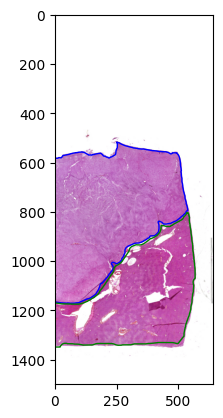

In [5]:
# Thumbnail with annotated regions
slide = openslide.OpenSlide("/content/drive/MyDrive/WSI_LHA0912-24/LHA0912-24_HES.mrxs")

# Load annotations
with open("/content/drive/MyDrive/WSI_LHA0912-24/LHA0912-24_HES.geojson") as f:
    data = json.load(f)

# Calculate scaling factors
thumbnail = slide.get_thumbnail((1500, 1500))

bx = int(slide.properties.get("openslide.bounds-x", 0))
by = int(slide.properties.get("openslide.bounds-y", 0))
bw = int(slide.properties.get("openslide.bounds-width", slide.dimensions[0]))
bh = int(slide.properties.get("openslide.bounds-height", slide.dimensions[1]))

sx = thumbnail.width / slide.dimensions[0]
sy = thumbnail.height / slide.dimensions[1]

# Plot thumbnail and annotations
plt.imshow(thumbnail)

Tumor = data["features"][0]
Nontumor = data['features'][1]

coords = Tumor['geometry']['coordinates'][0]
x = [(p[0] + bx) * sx for p in coords]
y = [(p[1] + by) * sy for p in coords]
plt.plot(x, y, "b-", linewidth=1)

coords = Nontumor['geometry']['coordinates'][0]
x = [(p[0] + bx) * sx for p in coords]
y = [(p[1] + by) * sy for p in coords]
plt.plot(x, y, "g-", linewidth=1)

plt.axis("on")
plt.show()

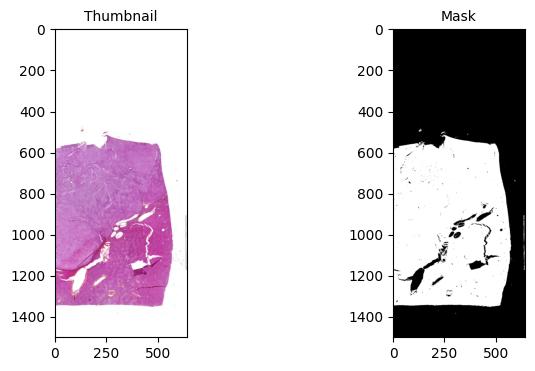

In [6]:
# Tissue mask
thumbnail = slide.get_thumbnail((1500, 1500))
img = np.array(thumbnail)

gray = img[:, :, 1]
mask = gray < 200

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(thumbnail)
plt.title("Thumbnail", fontdict={'size':10});

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Mask", fontdict={'size':10});

In [10]:
# Tesselation

#PARAMETERS#
lvl = 2
patch_size = int(1024*slide.level_downsamples[lvl])

# Get slide dimensions at level 0
slide_w, slide_h = slide.dimensions

# Get thumbnail dimensions to compute scaling factors
thumbnail = slide.get_thumbnail((1500, 1500))
thumb_w, thumb_h = thumbnail.size
scale_x = thumb_w / slide_w
scale_y = thumb_h / slide_h

# We will step through the grid with stride = patch_size
# To avoid extracting thousands of background patches, let's look at the tissue mask
img = np.array(thumbnail)
gray = img[:, :, 1]
mask = gray < 220

#ESTIMATING NUMBER OF EXTRACTED PATCHES#
total_grid_patches = 0
saved_patches_count = 0
patches = []

for y in range(0, slide_h, patch_size):
    for x in range(0, slide_w, patch_size):
        total_grid_patches += 1
        mask_x1 = int(x * scale_x)
        mask_y1 = int(y * scale_y)
        mask_x2 = int((x + patch_size) * scale_x)
        mask_y2 = int((y + patch_size) * scale_y)

        mask_patch = mask[mask_y1:mask_y2, mask_x1:mask_x2]

        if mask_patch.size > 0:
            tissue_proportion = np.mean(mask_patch)
        else:
            tissue_proportion = 0.0

        if tissue_proportion > 0.75:
            saved_patches_count += 1
            patches.append({
              "patch_id": f"LHA0912_patch_{saved_patches_count}",
              "x": x,
              "y": y,
              "width": patch_size,
              "height": patch_size,
              "level": 2,
              "tissue_fraction": f"{tissue_proportion:.1%}"})

print(f"Total grid positions evaluated: {total_grid_patches}")
print(f"Estimated patches to be extracted (tissue proportion > 75%): {saved_patches_count}")

#EXTRACTING PATCHES#
saved_patches_count = 0
for y in range(0, slide_h, patch_size):
    for x in range(0, slide_w, patch_size):
        # Map slide coordinates to mask coordinates
        mask_x1 = int(x * scale_x)
        mask_y1 = int(y * scale_y)
        mask_x2 = int((x + patch_size) * scale_x)
        mask_y2 = int((y + patch_size) * scale_y)

        # Extract the corresponding patch area from our mask
        mask_patch = mask[mask_y1:mask_y2, mask_x1:mask_x2]

        if mask_patch.size > 0:
            # Calculate tissue proportion
            tissue_proportion = np.mean(mask_patch)
        else:
            tissue_proportion = 0.0

        # Save patch only if it contains sufficient tissue (e.g. > 75%)
        if tissue_proportion > 0.75:
            saved_patches_count += 1
            patch_i = slide.read_region((x, y), lvl, (1000, 1000))
            patch_i.convert("RGB").save(f"/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_patches1024x1024/LHA0912_patch_{saved_patches_count}.png")
            #print(f"Saved: CMU-1_patch_{saved_patches_count}.png (Tissue Proportion: {tissue_proportion:.1%})")


Total grid positions evaluated: 900
Estimated patches to be extracted (tissue proportion > 75%): 348


In [11]:
# Save metadata table.
df = pd.DataFrame(patches)
df.to_csv("/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_patches.csv", index=False)

print(df)

              patch_id      x       y  width  height  level tissue_fraction
0      LHA0912_patch_1  32768   65536   4096    4096      2          100.0%
1      LHA0912_patch_2  36864   65536   4096    4096      2           90.7%
2      LHA0912_patch_3   4096   69632   4096    4096      2           98.8%
3      LHA0912_patch_4   8192   69632   4096    4096      2           99.6%
4      LHA0912_patch_5  12288   69632   4096    4096      2           98.3%
..                 ...    ...     ...    ...     ...    ...             ...
343  LHA0912_patch_344  40960  159744   4096    4096      2          100.0%
344  LHA0912_patch_345  45056  159744   4096    4096      2          100.0%
345  LHA0912_patch_346  49152  159744   4096    4096      2          100.0%
346  LHA0912_patch_347  53248  159744   4096    4096      2           99.8%
347  LHA0912_patch_348  57344  159744   4096    4096      2          100.0%

[348 rows x 7 columns]


In [24]:
# Classify paches as T or NT.
from shapely.geometry import Polygon, Point

# Get boundary offsets used during plotting
bx = int(slide.properties.get("openslide.bounds-x", 0))
by = int(slide.properties.get("openslide.bounds-y", 0))

# Create shapely polygons for Tumor and Nontumor regions
# Coordinates in GeoJSON are relative to the bounding box (bx, by)
tumor_coords = [(p[0] + bx, p[1] + by) for p in Tumor['geometry']['coordinates'][0]]
nontumor_coords = [(p[0] + bx, p[1] + by) for p in Nontumor['geometry']['coordinates'][0]]

tumor_poly = Polygon(tumor_coords)
nontumor_poly = Polygon(nontumor_coords)

def classify_patch(row):
    # Calculate the center of the patch
    center_x = row['x'] + (row['width'] / 2)
    center_y = row['y'] + (row['height'] / 2)
    point = Point(center_x, center_y)

    if tumor_poly.contains(point):
        return 'T'
    elif nontumor_poly.contains(point):
        return 'NT'
    else:
        return 'unknown'

# Apply classification
df['patch_type'] = df.apply(classify_patch, axis=1)

# Save updated dataframe
df.to_csv("/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_patches.csv", index=False)

# Display summary
print(df['patch_type'].value_counts())
display(df.head())

patch_type
T          205
NT         140
unknown      3
Name: count, dtype: int64


,patch_id,x,y,width,height,level,tissue_fraction,patch_type
0,LHA0912_patch_1,32768,65536,4096,4096,2,100.0%,T
1,LHA0912_patch_2,36864,65536,4096,4096,2,90.7%,T
2,LHA0912_patch_3,4096,69632,4096,4096,2,98.8%,T
3,LHA0912_patch_4,8192,69632,4096,4096,2,99.6%,T
4,LHA0912_patch_5,12288,69632,4096,4096,2,98.3%,T


In [34]:
# Feature extraction using ResNet-18
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

# Load pretrained image encoder: ResNet-18
from torchvision.models import resnet18, ResNet18_Weights

# Load pretrained ImageNet weights
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Remove the final 1000-class classification layer
model.fc = torch.nn.Identity()

# Prepare for inference, not training
model.eval()

# Use GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Use the preprocessing designed for these weights
preprocess = weights.transforms()

print("Device:", device)
print("Model ready")

# Run pretrained image encoder on all patches.
patch_dir = Path("/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_patches1024x1024/")

image_paths = [
  p for p in patch_dir.iterdir()
  if p.suffix.lower() in {".png", ".jpg", ".jpeg"}]

print("Number of patches:", len(image_paths))

if len(image_paths) == 0:
  raise ValueError("No images found. Check patch_dir.")

# Batch analysis
from torch.utils.data import Dataset, DataLoader

class PatchDataset(Dataset):
  def __init__(self, paths, transform):
    self.paths = paths
    self.transform = transform

  def __len__(self):
    return len(self.paths)

  def __getitem__(self, index):
    path = self.paths[index]

    with Image.open(path) as image:
      image = image.convert("RGB")
      tensor = self.transform(image)
    return tensor, str(path)

dataset = PatchDataset(image_paths, preprocess)

loader = DataLoader(
      dataset,
      batch_size=32,
      shuffle=False,
      num_workers=0)

all_embeddings = []
all_paths = []

with torch.inference_mode():
  for images, paths in loader:
    images = images.to(device)
    features = model(images)
    all_embeddings.append(features.cpu().numpy())
    all_paths.extend(paths)

embeddings = np.concatenate(all_embeddings, axis=0)
print("Embedding matrix:", embeddings.shape)

# Save the results.
output_dir = Path("/content/drive/MyDrive/WSI_LHA0912-24/")
output_dir.mkdir(parents=True, exist_ok=True)

# Embeddings
np.save(output_dir / "embeddings.npy", embeddings)

# Metadata table
df['patch_path'] = all_paths
df['embedding_row'] = np.arange(len(all_paths))

df.to_csv("/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_patches.csv", index=False)

display(df.head())
print("Saved embeddings and metadata.")

PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
Device: CPU
Device: cpu
Model ready
Number of patches: 348
Embedding matrix: (348, 512)


,patch_id,x,y,width,height,level,tissue_fraction,patch_type,patch_path,embedding_row
0,LHA0912_patch_1,32768,65536,4096,4096,2,100.0%,T,/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_...,0
1,LHA0912_patch_2,36864,65536,4096,4096,2,90.7%,T,/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_...,1
2,LHA0912_patch_3,4096,69632,4096,4096,2,98.8%,T,/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_...,2
3,LHA0912_patch_4,8192,69632,4096,4096,2,99.6%,T,/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_...,3
4,LHA0912_patch_5,12288,69632,4096,4096,2,98.3%,T,/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_...,4


Saved embeddings and metadata.


PCA shape: (348, 2)
Explained variance ratio [0.20465006 0.11769225]
Variance explained by three components: 0.322


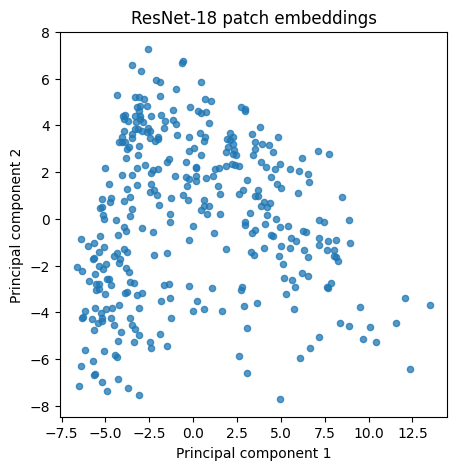

In [55]:
# PCA plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Load data
embeddings = np.load(Path("/content/drive/MyDrive/WSI_LHA0912-24/") / "embeddings.npy")
metadata = pd.read_csv(Path("/content/drive/MyDrive/WSI_LHA0912-24/") / "LHA0912_patches.csv")

# Reduce 512 features to 2 dimensions
pca = PCA(n_components=2)
embedding_2d = pca.fit_transform(embeddings)

print("PCA shape:", embedding_2d.shape)
print("Explained variance ratio", pca.explained_variance_ratio_)
print("Variance explained by three components:",
    round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(5, 5))
plt.scatter(
    embedding_2d[:, 0],
    embedding_2d[:, 1],
    s=20,
    alpha=0.75)

plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("ResNet-18 patch embeddings")
plt.show()

# Save PCA coordinates to the metadata
#metadata["PC1"] = embedding_2d[:, 0]
#metadata["PC2"] = embedding_2d[:, 1]

#metadata.to_csv("/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_patches.csv", index=False)

,patch_id,x,y,width,height,level,tissue_fraction,patch_type,patch_path,embedding_row,PC1,PC2
0,LHA0912_patch_1,32768,65536,4096,4096,2,100.0%,T,/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_...,0,-4.417658,-0.039851
1,LHA0912_patch_2,36864,65536,4096,4096,2,90.7%,T,/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_...,1,-1.911476,-4.919014
2,LHA0912_patch_3,4096,69632,4096,4096,2,98.8%,T,/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_...,2,-3.962987,0.781500
3,LHA0912_patch_4,8192,69632,4096,4096,2,99.6%,T,/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_...,3,-3.475976,0.412431
4,LHA0912_patch_5,12288,69632,4096,4096,2,98.3%,T,/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_...,4,-1.467228,-1.472697


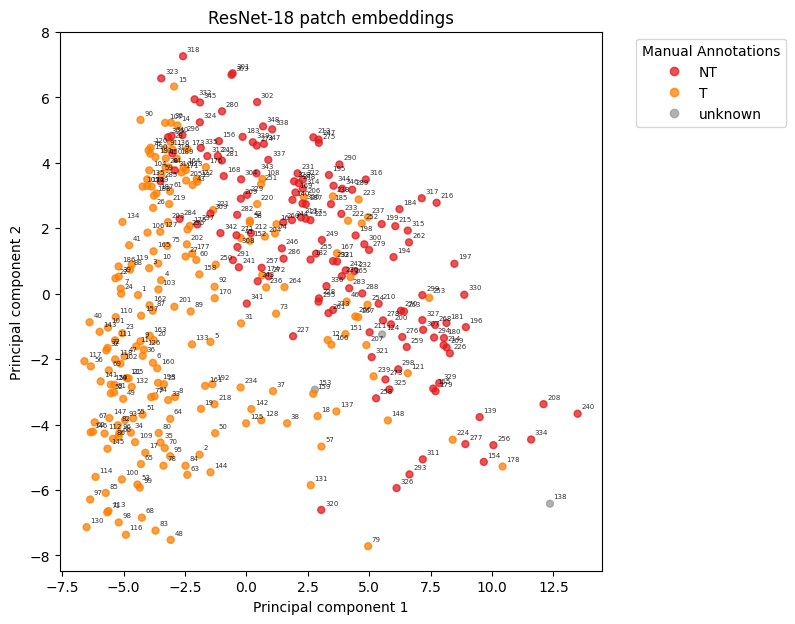

In [56]:
# Color by your own annotation.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# metadata loading with PCA coordinates
metadata = pd.read_csv(Path("/content/drive/MyDrive/WSI_LHA0912-24/") / "LHA0912_patches.csv", sep=",")
display(metadata.head())

# Convert categorical string annotations to numeric codes for plotting
category_codes = metadata["patch_type"].astype('category')

plt.figure(figsize=(7, 7))
scatter = plt.scatter(
    metadata["PC1"],
    metadata["PC2"],
    c=category_codes.cat.codes,
    cmap="Set1",
    s=25,
    alpha=0.75)

# Add patch_id
for idx, row in metadata.iterrows():
    plt.text(
        row["PC1"] + 0.15,  # Léger décalage en X pour la lisibilité
        row["PC2"] + 0.15,  # Léger décalage en Y
        str(idx + 1),
        fontsize=5,
        alpha=0.8
    )

# Retrieve unique categories in the order of their codes to match the legend
labels = list(category_codes.cat.categories)

plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("ResNet-18 patch embeddings")

plt.legend(handles=scatter.legend_elements()[0], labels=labels, title="Manual Annotations", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

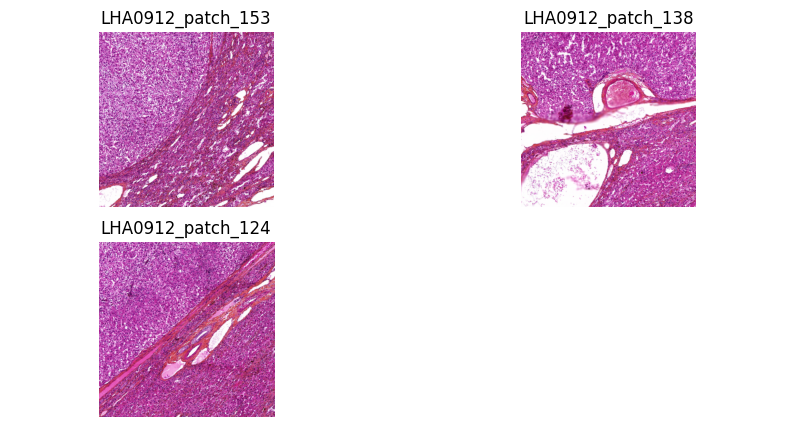

In [57]:
# Show corresponding patches.
patches = [153, 138, 124] # "unknown" patch type.

plt.figure(figsize=(10,5))
plt.axis("off")
for img in patches:
  plt.subplot(2, int(len(patches)/2+1), patches.index(img)+1)
  plt.imshow(plt.imread(f"/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_patches1024x1024/LHA0912_patch_{img}.png"))
  plt.title(f"LHA0912_patch_{img}")
  plt.axis("off")

plt.show()

In [59]:
# Classifier training.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import random

# Divide patches into train patches (80%) and test patches (20%)
from sklearn.model_selection import train_test_split

metadata = pd.read_csv(Path("/content/drive/MyDrive/WSI_LHA0912-24/") / "LHA0912_patches.csv", sep=",")
embeddings = np.load(Path("/content/drive/MyDrive/WSI_LHA0912-24/") / "embeddings.npy")

random.seed(45)
X_train, X_test, Y_train, Y_test = train_test_split(
    embeddings, # embeddings: array of shape (number_of_patches, 512)
    metadata["patch_type"], # labels: one label per patch, in the same order as embeddings
    test_size=0.2,
    random_state=42,
    stratify=metadata["patch_type"]
)

print("X_train = embeddings used to train the model:", X_train.shape)
print("Y_train = labels used to train the model:", Y_train.shape)
print("X_test = embeddings used to test the model:", X_test.shape)
print("Y_test = labels used as ground truth to evaluate perfomance:", Y_test.shape)

# Train the classifier and test it
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

model = LogisticRegression(max_iter=1000) # Load the model
model.fit(X_train, Y_train) # Learn from the training data
Y_pred = model.predict(X_test) # Predict labels for held-out patches

print(classification_report(Y_test, Y_pred))

X_train = embeddings used to train the model: (278, 512)
Y_train = labels used to train the model: (278,)
X_test = embeddings used to test the model: (70, 512)
Y_test = labels used as ground truth to evaluate perfomance: (70,)
              precision    recall  f1-score   support

          NT       0.96      0.96      0.96        28
           T       0.98      1.00      0.99        41
     unknown       0.00      0.00      0.00         1

    accuracy                           0.97        70
   macro avg       0.65      0.65      0.65        70
weighted avg       0.96      0.97      0.96        70



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


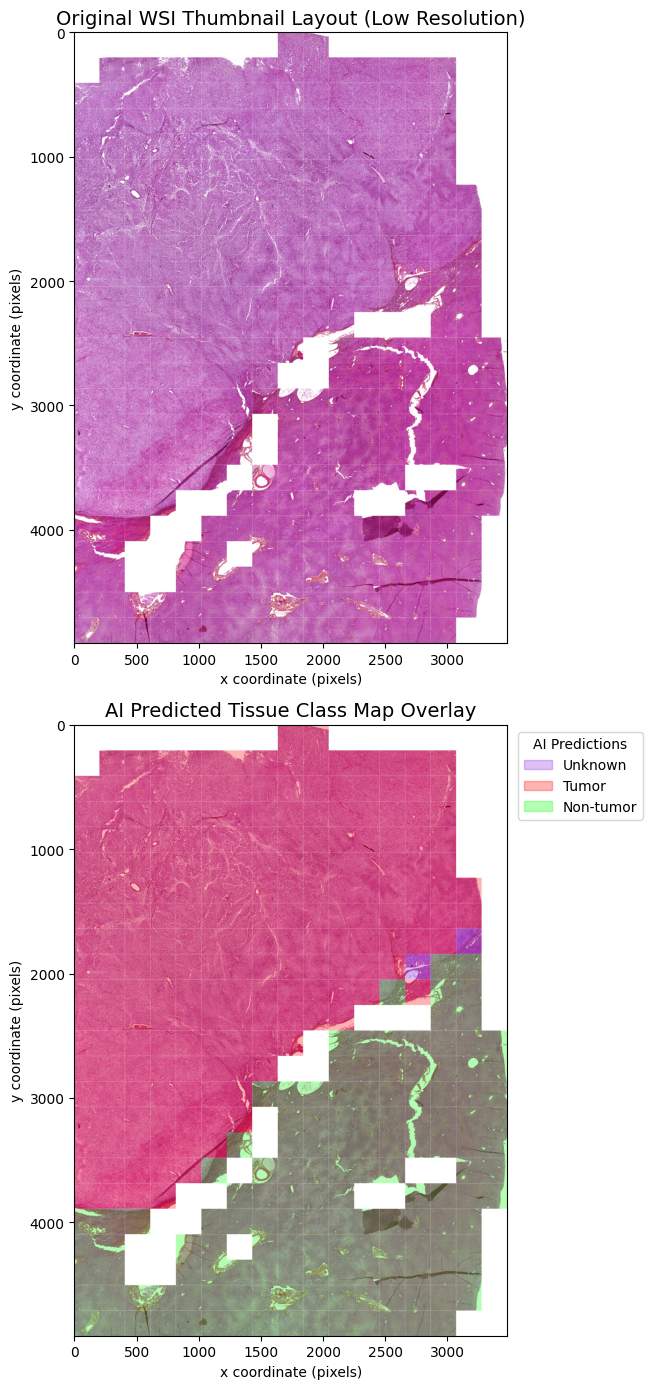

In [71]:
# Create the AI map.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
from pathlib import Path

# 1. Retrieve the metadata with coordinates and embeddings
metadata = pd.read_csv(Path("/content/drive/MyDrive/WSI_LHA0912-24/") / "LHA0912_patches.csv", sep=",")
embeddings = np.load(Path("/content/drive/MyDrive/WSI_LHA0912-24/") / "embeddings.npy")

# 2. Predict the class for ALL patches using our trained model
# (We use the 'model' trained on the 80% split in cell aAXziaQoDNbs)
all_predictions = model.predict(embeddings)
metadata["predicted_patch_type"] = all_predictions

# 3. Setup canvas coordinates and scaling factor
lvl = 2
scaling_factor = 0.05
patch_size_scaled = int(1024*slide.level_downsamples[lvl] * scaling_factor)

x_coords = metadata["x"]
y_coords = metadata["y"]

x_coords_scaled = x_coords * scaling_factor
y_coords_scaled = y_coords * scaling_factor

x_coords_scaled_offset = x_coords_scaled - x_coords_scaled.min()
y_coords_scaled_offset = y_coords_scaled - y_coords_scaled.min()

height = int(y_coords_scaled_offset.max() + patch_size_scaled)

width = int(x_coords_scaled_offset.max() + patch_size_scaled)

# Create two canvases:
# - One for the clean, original thumbnail layout
# - One for the AI prediction overlay map
canvas_thumbnail = Image.new("RGB", (width, height), "white")
canvas_prediction = Image.new("RGB", (width, height), "white")

# Define colors with transparency (RGBA) for each predicted patch type
colors_rgba = {
    "unknown": (138, 43, 226, 75),  # Violet (unknown)
    "T": (255, 0, 0, 75),     # Red (T)
    "NT": (0, 255, 0, 75)    # Green (NT)
}

# 4. Paste each resized patch into the canvases
for idx, img_id in enumerate(metadata["patch_id"]):
    # Load and resize patch
    patch_path = Path("/content/drive/MyDrive/WSI_LHA0912-24/LHA0912_patches1024x1024/") / f"{img_id}.png"
    patch = Image.open(patch_path).convert("RGB")
    patch_resized = patch.resize((patch_size_scaled, patch_size_scaled))

    # Paste into both canvases
    x_paste = int(x_coords_scaled_offset[idx])
    y_paste = int(y_coords_scaled_offset[idx])

    canvas_thumbnail.paste(patch_resized, (x_paste, y_paste))
    canvas_prediction.paste(patch_resized, (x_paste, y_paste))

    # Generate and apply overlay to the prediction map
    pred_type = metadata.loc[idx, "predicted_patch_type"]
    color = colors_rgba.get(pred_type, (255, 255, 255, 0))

    overlay = Image.new("RGBA", (patch_size_scaled, patch_size_scaled), color)
    canvas_prediction.paste(overlay, (x_paste, y_paste), overlay)

# 5. Display both maps side-by-side
fig, axes = plt.subplots(2, 1, figsize=(18, 14))

# Ax 1: Original Thumbnail Layout
axes[0].imshow(canvas_thumbnail)
axes[0].set_title("Original WSI Thumbnail Layout (Low Resolution)", fontsize=14)
axes[0].axis("on")
axes[0].set_xlabel("x coordinate (pixels)")
axes[0].set_ylabel("y coordinate (pixels)")

# Ax 2: AI Predicted Map Overlay
axes[1].imshow(canvas_prediction)
axes[1].set_title("AI Predicted Tissue Class Map Overlay", fontsize=14)
axes[1].axis("on")
axes[1].set_xlabel("x coordinate (pixels)")
axes[1].set_ylabel("y coordinate (pixels)")

# Setup Legend
labels = ["Unknown", "Tumor", "Non-tumor"]
legend_handles = [
    mpatches.Patch(color=np.array(colors_rgba["unknown"])/255.0, label=labels[0]),
    mpatches.Patch(color=np.array(colors_rgba["T"])/255.0, label=labels[1]),
    mpatches.Patch(color=np.array(colors_rgba["NT"])/255.0, label=labels[2])
]
axes[1].legend(handles=legend_handles, title="AI Predictions", bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.show()

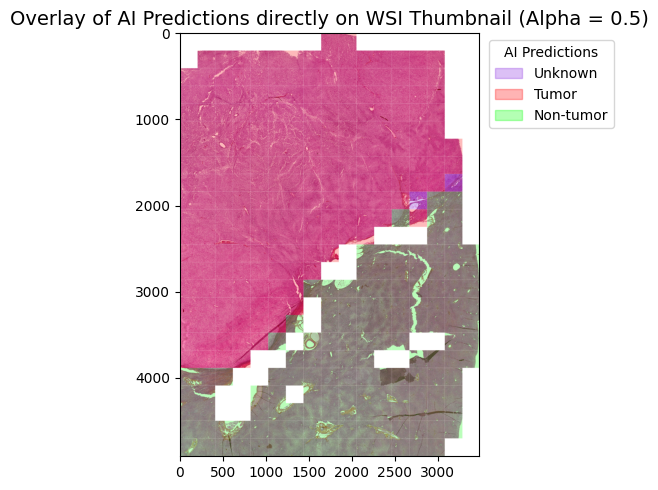

In [75]:
# Overlay predictions on the thumbnail.
plt.figure(figsize=(10, 5))
plt.imshow(canvas_thumbnail)
plt.imshow(canvas_prediction, alpha=0.9)

# Setup the same legend and styling
labels = ["Unknown", "Tumor", "Non-tumor"]
legend_handles = [
    mpatches.Patch(color=np.array(colors_rgba["unknown"])/255.0, label=labels[0]),
    mpatches.Patch(color=np.array(colors_rgba["T"])/255.0, label=labels[1]),
    mpatches.Patch(color=np.array(colors_rgba["NT"])/255.0, label=labels[2])
]
plt.legend(handles=legend_handles, title="AI Predictions", bbox_to_anchor=(1.01, 1), loc='upper left')

plt.title("Overlay of AI Predictions directly on WSI Thumbnail (Alpha = 0.5)", fontsize=14)
plt.axis("on")
plt.tight_layout()
plt.show()